## Librairies

In [1]:
# Optional: install NLTK (kept commented out as in the original notebook).
#!pip install nltk

In [2]:
# ----------------------------------------------------------------------
# 1. Libraries
# ----------------------------------------------------------------------
# - pandas / NumPy: data handling
# - Matplotlib / Seaborn: visualisation
# - scikit-learn: bag-of-words vectorisation, train/test split, cross-validation,
#   grid search, classifiers and evaluation metrics
# - XGBoost: gradient-boosted tree classifier (XGBClassifier)
# - NLTK: English stop-word list and Porter stemmer for text preprocessing
# nltk.download('stopwords') fetches the stop-word corpus if it is not already installed.
# Warnings are silenced to keep the notebook output readable.
# Note: some imported names are not used in this notebook; the import list is kept as in the original.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import CountVectorizer

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from sklearn.metrics import roc_curve, auc


from sklearn.metrics import accuracy_score , recall_score , f1_score, classification_report,matthews_corrcoef,precision_score,confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn import metrics

import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer

import string


import warnings
warnings.filterwarnings('ignore')



[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\aliga\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


## Spam Mails Dataset

In [3]:
# Optional: extract the dataset archive (Google Colab path; kept commented out as in the original).
#! unzip /content/spam-mails-dataset.zip

In [4]:
# ----------------------------------------------------------------------
# 2. Data loading
# ----------------------------------------------------------------------
# Load the Spam Mails dataset (spam_ham_dataset.csv) into a pandas DataFrame.
# NOTE: this is the original absolute Windows path used by the author. To run the
# notebook elsewhere, point it to your local copy of the file (see data/README.md).
data_spam = pd.read_csv(r'C:\Users\aliga\Downloads\mailspam\spam_ham_dataset.csv')

In [5]:
# Preview the first five rows of the raw dataset.
data_spam.head()

,Unnamed: 0,label,text,label_num
0,605,ham,Subject: enron methanol ; meter # : 988291\r\n...,0
1,2349,ham,"Subject: hpl nom for january 9 , 2001\r\n( see...",0
2,3624,ham,"Subject: neon retreat\r\nho ho ho , we ' re ar...",0
3,4685,spam,"Subject: photoshop , windows , office . cheap ...",1
4,2030,ham,Subject: re : indian springs\r\nthis deal is t...,0


In [6]:
# Dataset dimensions: (number of e-mails, number of columns).
data_spam.shape

(5171, 4)

The files contains 5171 lines and 4 columns

In [7]:
# Column data types and non-null counts.
data_spam.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5171 entries, 0 to 5170
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  5171 non-null   int64 
 1   label       5171 non-null   object
 2   text        5171 non-null   object
 3   label_num   5171 non-null   int64 
dtypes: int64(2), object(2)
memory usage: 161.7+ KB


## Data Description


*   Unname:0 : not interesting , it is just an id
*   label : it is the object label of the dataset between two catgeoris ( ham and spam )
*   text  : It is the text mail
* label_num : A representation of label in numerical way to train a mail so we dont have to transformer the label data, 0 : ham , 1 : spam       



In [8]:
# ----------------------------------------------------------------------
# 3. Data cleaning
# ----------------------------------------------------------------------
# Keep the list of column names; columns[0] ('Unnamed: 0') is dropped below.
columns = data_spam.columns

In [9]:
# Display the column names.
columns

Index(['Unnamed: 0', 'label', 'text', 'label_num'], dtype='object')

In [10]:
# Remove the 'Unnamed: 0' identifier column, which carries no predictive information.
# drop unnamed columns , we dont need the id

data_spam.drop(columns[0],axis=1,inplace=True)     # inplace true when you  apply drop or others function , it will change the dataset.

In [11]:
# Inspect the dataset after removing the identifier column.
data_spam

,label,text,label_num
0,ham,Subject: enron methanol ; meter # : 988291\r\n...,0
1,ham,"Subject: hpl nom for january 9 , 2001\r\n( see...",0
2,ham,"Subject: neon retreat\r\nho ho ho , we ' re ar...",0
3,spam,"Subject: photoshop , windows , office . cheap ...",1
4,ham,Subject: re : indian springs\r\nthis deal is t...,0
...,...,...,...
5166,ham,Subject: put the 10 on the ft\r\nthe transport...,0
5167,ham,Subject: 3 / 4 / 2000 and following noms\r\nhp...,0
5168,ham,Subject: calpine daily gas nomination\r\n>\r\n...,0
5169,ham,Subject: industrial worksheets for august 2000...,0


In [12]:
# Descriptive statistics of the numeric target column (label_num).
# Statistics values
data_spam.describe()

,label_num
count,5171.000000
mean,0.289886
std,0.453753
min,0.000000
25%,0.000000
50%,0.000000
75%,1.000000
max,1.000000


In [13]:
# Count missing values per column.
# to check if there is an nan value in dataset
data_spam.isna().sum()

label        0
text         0
label_num    0
dtype: int64

In [14]:
# Boolean mask of fully duplicated rows (identical label, text and label_num).
data_spam.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
5166    False
5167    False
5168     True
5169    False
5170    False
Length: 5171, dtype: bool

In [15]:
# Positional indices of the duplicated rows.
# find all the duplicated values in order to drop it
duplicated_indices=np.where(data_spam.duplicated())[0]

In [16]:
# Display the duplicated rows.
data_spam.iloc[duplicated_indices]

,label,text,label_num
182,spam,Subject: \r\n,1
296,spam,Subject: \r\n,1
363,spam,Subject: \r\n,1
436,ham,Subject: cornhusker up on 24 th\r\nspoke with ...,0
624,ham,"Subject: enron / hpl actuals for november 13 ,...",0
...,...,...,...
5061,ham,Subject: tenaska iv\r\nbob :\r\ni understand f...,0
5064,spam,Subject: \r\nthis week only : f . ree gen . er...,1
5089,spam,Subject: \r\nthe permanent fix to penis growth...,1
5155,ham,Subject: cleburne - tenaska iv plant\r\ndaren ...,0


In [17]:
# Remove duplicated rows (the first occurrence of each row is kept).
# drop all the duplicate value
data_spam.drop_duplicates(inplace=True)

In [18]:
# Inspect the dataset after de-duplication.
data_spam

,label,text,label_num
0,ham,Subject: enron methanol ; meter # : 988291\r\n...,0
1,ham,"Subject: hpl nom for january 9 , 2001\r\n( see...",0
2,ham,"Subject: neon retreat\r\nho ho ho , we ' re ar...",0
3,spam,"Subject: photoshop , windows , office . cheap ...",1
4,ham,Subject: re : indian springs\r\nthis deal is t...,0
...,...,...,...
5165,ham,"Subject: fw : crosstex energy , driscoll ranch...",0
5166,ham,Subject: put the 10 on the ft\r\nthe transport...,0
5167,ham,Subject: 3 / 4 / 2000 and following noms\r\nhp...,0
5169,ham,Subject: industrial worksheets for august 2000...,0


In [19]:
# Reset the row index to 0..n-1 after de-duplication (the old index is stored in an 'index' column).
# A contiguous index is needed by the index-based preprocessing loop further below.
data_spam.reset_index(inplace=True)

In [20]:
# Inspect the dataset with the new index.
data_spam

,index,label,text,label_num
0,0,ham,Subject: enron methanol ; meter # : 988291\r\n...,0
1,1,ham,"Subject: hpl nom for january 9 , 2001\r\n( see...",0
2,2,ham,"Subject: neon retreat\r\nho ho ho , we ' re ar...",0
3,3,spam,"Subject: photoshop , windows , office . cheap ...",1
4,4,ham,Subject: re : indian springs\r\nthis deal is t...,0
...,...,...,...,...
4988,5165,ham,"Subject: fw : crosstex energy , driscoll ranch...",0
4989,5166,ham,Subject: put the 10 on the ft\r\nthe transport...,0
4990,5167,ham,Subject: 3 / 4 / 2000 and following noms\r\nhp...,0
4991,5169,ham,Subject: industrial worksheets for august 2000...,0


In [21]:
# Drop the old index column created by reset_index().
data_spam.drop(columns=["index"],inplace=True)

In [22]:
# Inspect the cleaned dataset.
data_spam

,label,text,label_num
0,ham,Subject: enron methanol ; meter # : 988291\r\n...,0
1,ham,"Subject: hpl nom for january 9 , 2001\r\n( see...",0
2,ham,"Subject: neon retreat\r\nho ho ho , we ' re ar...",0
3,spam,"Subject: photoshop , windows , office . cheap ...",1
4,ham,Subject: re : indian springs\r\nthis deal is t...,0
...,...,...,...
4988,ham,"Subject: fw : crosstex energy , driscoll ranch...",0
4989,ham,Subject: put the 10 on the ft\r\nthe transport...,0
4990,ham,Subject: 3 / 4 / 2000 and following noms\r\nhp...,0
4991,ham,Subject: industrial worksheets for august 2000...,0


In [23]:
# Sanity check: number of remaining duplicated rows (expected 0).
# check if there is any ramain duplicated value
data_spam.duplicated().sum()

0

In [24]:
# ----------------------------------------------------------------------
# 4. Exploratory analysis: class distribution
# ----------------------------------------------------------------------
# Percentage of ham and spam e-mails.
# count in percentage of categories in a columns
data_spam.label.value_counts()/data_spam.shape[0]*100

label
ham     70.719007
spam    29.280993
Name: count, dtype: float64

In [25]:
# Class names, ordered by frequency.
# index of the categories number
data_spam.label.value_counts().index

Index(['ham', 'spam'], dtype='object', name='label')

In [26]:
# Absolute number of e-mails per class.
# data_spam['label'] == data_spam.label

data_spam.label.value_counts()

label
ham     3531
spam    1462
Name: count, dtype: int64

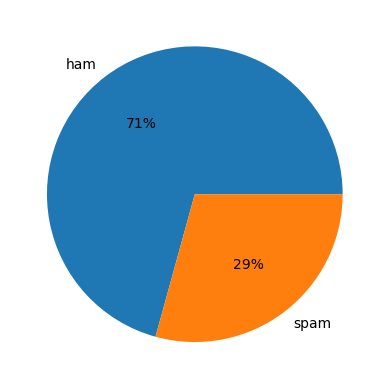

In [27]:
# Pie chart of the class distribution. plt.savefig("pie chart") also writes the figure
# to the working directory as 'pie chart.png'.
plt.plot(figsize=(10,7))
plt.pie(x=data_spam['label'].value_counts(),labels=data_spam.label.value_counts().index,autopct='%.0f%%')
plt.savefig("pie chart")
plt.show()



The dataset is not balanced, we do have to be careful when we train the model

In [28]:
# Consistency check: map the text labels to integers (ham -> 0, spam -> 1) in a helper column 'chek_label'.
dict_label={'ham':0,'spam':1}

data_spam['chek_label']= data_spam['label'].map(dict_label)


In [29]:
# Sum of the differences between 'label_num' and the mapping above (0 is consistent with label_num = 0 for ham, 1 for spam).
(data_spam['label_num']-data_spam['chek_label']).sum()

0

In [30]:
# Display the raw e-mail texts.
print(data_spam['text'])

0       Subject: enron methanol ; meter # : 988291\r\n...
1       Subject: hpl nom for january 9 , 2001\r\n( see...
2       Subject: neon retreat\r\nho ho ho , we ' re ar...
3       Subject: photoshop , windows , office . cheap ...
4       Subject: re : indian springs\r\nthis deal is t...
                              ...                        
4988    Subject: fw : crosstex energy , driscoll ranch...
4989    Subject: put the 10 on the ft\r\nthe transport...
4990    Subject: 3 / 4 / 2000 and following noms\r\nhp...
4991    Subject: industrial worksheets for august 2000...
4992    Subject: important online banking alert\r\ndea...
Name: text, Length: 4993, dtype: object


### Features engineering for the text

In [31]:
# ----------------------------------------------------------------------
# 5. Text preprocessing
# ----------------------------------------------------------------------
# Replace line breaks with spaces. Note: the replacement string is a single space ' '
# (not an empty string as the original comment below says), so line breaks become word separators.
# This line of code replaces any occurrence of '\r\n', '\r', or '\n' in the 'text' column with an empty string, effectively removing them
data_spam['filtered_message']=data_spam['text'].replace(r'\r\n|\r|\n', ' ', regex=True)

In [32]:
# Inspect the dataset with the new 'filtered_message' column.
data_spam

,label,text,label_num,chek_label,filtered_message
0,ham,Subject: enron methanol ; meter # : 988291\r\n...,0,0,Subject: enron methanol ; meter # : 988291 thi...
1,ham,"Subject: hpl nom for january 9 , 2001\r\n( see...",0,0,"Subject: hpl nom for january 9 , 2001 ( see at..."
2,ham,"Subject: neon retreat\r\nho ho ho , we ' re ar...",0,0,"Subject: neon retreat ho ho ho , we ' re aroun..."
3,spam,"Subject: photoshop , windows , office . cheap ...",1,1,"Subject: photoshop , windows , office . cheap ..."
4,ham,Subject: re : indian springs\r\nthis deal is t...,0,0,Subject: re : indian springs this deal is to b...
...,...,...,...,...,...
4988,ham,"Subject: fw : crosstex energy , driscoll ranch...",0,0,"Subject: fw : crosstex energy , driscoll ranch..."
4989,ham,Subject: put the 10 on the ft\r\nthe transport...,0,0,Subject: put the 10 on the ft the transport vo...
4990,ham,Subject: 3 / 4 / 2000 and following noms\r\nhp...,0,0,Subject: 3 / 4 / 2000 and following noms hpl c...
4991,ham,Subject: industrial worksheets for august 2000...,0,0,Subject: industrial worksheets for august 2000...


In [33]:
# Illustrative stemming example (commented out in the original; not part of the pipeline).
#Example
# ps = PorterStemmer()

# words = ["running", "ran", "runs", "goes", "going"]
# stemmed_words = [ps.stem(word) for word in words]

# print(stemmed_words)

In [34]:
# Initialise the Porter stemmer and the list that will hold the preprocessed e-mails.
ps = PorterStemmer() # Initialize a porterStemer object , it is used to find the root of the words , for e.g "running" --> "run"
corpus = [] # where we put all our stemmed text,

In [35]:
# Load the NLTK English stop-word list (displayed below).

all_stop_words = set(stopwords.words('english')) # stops words mean, the commons words that we find values for our analysis. Examples of stop words in English include "the", "is", "and", "in", "at", "on", "it", "of", etc.
all_stop_words

{'a',
 'about',
 'above',
 'after',
 'again',
 'against',
 'ain',
 'all',
 'am',
 'an',
 'and',
 'any',
 'are',
 'aren',
 "aren't",
 'as',
 'at',
 'be',
 'because',
 'been',
 'before',
 'being',
 'below',
 'between',
 'both',
 'but',
 'by',
 'can',
 'couldn',
 "couldn't",
 'd',
 'did',
 'didn',
 "didn't",
 'do',
 'does',
 'doesn',
 "doesn't",
 'doing',
 'don',
 "don't",
 'down',
 'during',
 'each',
 'few',
 'for',
 'from',
 'further',
 'had',
 'hadn',
 "hadn't",
 'has',
 'hasn',
 "hasn't",
 'have',
 'haven',
 "haven't",
 'having',
 'he',
 'her',
 'here',
 'hers',
 'herself',
 'him',
 'himself',
 'his',
 'how',
 'i',
 'if',
 'in',
 'into',
 'is',
 'isn',
 "isn't",
 'it',
 "it's",
 'its',
 'itself',
 'just',
 'll',
 'm',
 'ma',
 'me',
 'mightn',
 "mightn't",
 'more',
 'most',
 'mustn',
 "mustn't",
 'my',
 'myself',
 'needn',
 "needn't",
 'no',
 'nor',
 'not',
 'now',
 'o',
 'of',
 'off',
 'on',
 'once',
 'only',
 'or',
 'other',
 'our',
 'ours',
 'ourselves',
 'out',
 'over',
 'own',
 'r

In [36]:
# Remove 'not' from the stop-word list so that negations are kept as features.
# exmaple
all_stop_words.remove('not')

In [37]:
# Display the messages before tokenisation.
print(data_spam['filtered_message'])

0       Subject: enron methanol ; meter # : 988291 thi...
1       Subject: hpl nom for january 9 , 2001 ( see at...
2       Subject: neon retreat ho ho ho , we ' re aroun...
3       Subject: photoshop , windows , office . cheap ...
4       Subject: re : indian springs this deal is to b...
                              ...                        
4988    Subject: fw : crosstex energy , driscoll ranch...
4989    Subject: put the 10 on the ft the transport vo...
4990    Subject: 3 / 4 / 2000 and following noms hpl c...
4991    Subject: industrial worksheets for august 2000...
4992    Subject: important online banking alert dear v...
Name: filtered_message, Length: 4993, dtype: object


In [38]:
# Preprocess every e-mail and store the result in `corpus`:
#   1. convert to lower case
#   2. remove punctuation characters (string.punctuation)
#   3. split on whitespace into tokens
#   4. discard stop words ('not' is retained) and apply Porter stemming
#   5. join the tokens back into a single string
for i in range(len(data_spam)):
    if i < len(data_spam):
        text = data_spam['filtered_message'][i].lower().translate(str.maketrans('', '', string.punctuation)).split()
        text = [ps.stem(word) for word in text if word not in all_stop_words]
        text = ' '.join(text)
        corpus.append(text)

In [39]:
# ----------------------------------------------------------------------
# 6. Feature extraction: bag-of-words
# ----------------------------------------------------------------------
# CountVectorizer with default settings builds a document-term matrix of raw token counts.
# Note: the vectorizer is fitted on the whole corpus, before the train/test split.

# Initialize the CountVectorizer
# count_vectorizer = CountVectorizer(stop_words='english')
count_vectorizer = CountVectorizer()
# Fit the vectorizer to the text and transform the text into a count matrix
count_matrix = count_vectorizer.fit_transform(corpus)

print("Count Matrix:")
print(count_matrix.toarray())


Count Matrix:
[[1 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 4 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]


In [40]:
# Shape of the document-term matrix: (number of e-mails, vocabulary size).
count_matrix.shape

(4993, 42638)

In [41]:
# Toy CountVectorizer example (commented out in the original; not part of the pipeline).
# corpus = [
#      'This is the first document.',
#      'This document is the second document.',
#      'And this is the third one.',
#      'Is this the first document?',
#  ]

In [42]:
# Exploratory code, commented out in the original (not executed).
# # Initialize the CountVectorizer
# count_vectorizer = CountVectorizer()

In [43]:
# Exploratory code, commented out in the original (not executed).
# X = count_vectorizer.fit_transform(corpus)

In [44]:
# Exploratory code, commented out in the original (not executed).
# count_vectorizer.get_feature_names_out()

In [45]:
# Exploratory code, commented out in the original (not executed).
# X.toarray()

# Create model

In [46]:
# ----------------------------------------------------------------------
# 7. Features and target
# ----------------------------------------------------------------------
# x: bag-of-words count matrix; y: binary target (0 = ham, 1 = spam).
x = count_matrix
y = data_spam['label_num']

In [47]:
# Train/test split: 80% training, 20% testing (test_size=.2), with shuffling (scikit-learn default).
# No random_state is set and the split is not stratified, so the split - and every score
# computed from it - differs from one run to the next.
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=.2)

## Model objects and helper carried over from the 80/20 notebook (not evaluated here)

# Model

In [48]:
# ----------------------------------------------------------------------
# 8. Baseline model definitions (not evaluated in this notebook)
# ----------------------------------------------------------------------
# These objects are carried over from the 80/20 notebook; every cal() call below is
# commented out, so none of them is trained here.
# Note: model1 is created with penalty=['l1'] (a list). scikit-learn would reject this
# value at fit time, but model1 is never fitted, so it has no effect on the results.
model1=LogisticRegression(penalty=['l1'])
model2= RandomForestClassifier()
model3=SVC()
model4=GradientBoostingClassifier(n_estimators=1000)
model5=MLPClassifier()
model6=KNeighborsClassifier()
model7=DecisionTreeClassifier()

## Experiment 2 — Hyperparameter tuning with GridSearchCV (5-fold CV on the training set)

# Hyperparameter 

In [57]:
# ----------------------------------------------------------------------
# Hyperparameter tuning 1/5: XGBoost
# ----------------------------------------------------------------------
# Grid: 3 x 3 x 3 x 3 = 81 combinations; 5-fold CV on the training set; scoring = accuracy.
# The best estimator (refitted on the full training set, GridSearchCV default refit=True)
# is evaluated on the test set. Metrics are called as metric(y_test, y_pred), the standard order.
# Define the model
xgb_model = XGBClassifier(use_label_encoder=False, eval_metric='logloss')

# Define the parameter grid
param_grid_xgb = {
    'n_estimators': [50, 100, 150],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 5, 7],
    'subsample': [0.7, 0.8, 0.9]
}

# Configure and run GridSearchCV
grid_search_xgb = GridSearchCV(estimator=xgb_model, param_grid=param_grid_xgb, cv=5, scoring='accuracy', verbose=1)
grid_search_xgb.fit(x_train, y_train)

# Display best parameters and best cross-validation accuracy
print(f"Best parameters found: {grid_search_xgb.best_params_}")
print(f"Best cross-validation accuracy: {grid_search_xgb.best_score_}")

# Get the best model and make predictions on the test set
best_model_xgb = grid_search_xgb.best_estimator_
y_pred_xgb = best_model_xgb.predict(x_test)

# Evaluate the model with various metrics
print(f"Accuracy on the testing set: {accuracy_score(y_test, y_pred_xgb)}")
print(f"F1 Score on the testing set: {f1_score(y_test, y_pred_xgb)}")
print(f"Recall on the testing set: {recall_score(y_test, y_pred_xgb)}")
print(f"Precision on the testing set: {precision_score(y_test, y_pred_xgb)}")
print(f"MCC on the testing set: {matthews_corrcoef(y_test, y_pred_xgb)}")

Fitting 5 folds for each of 81 candidates, totalling 405 fits
Best parameters found: {'learning_rate': 0.2, 'max_depth': 7, 'n_estimators': 150, 'subsample': 0.9}
Best cross-validation accuracy: 0.9697071213703847
Accuracy on the testing set: 0.96996996996997
F1 Score on the testing set: 0.953416149068323
Recall on the testing set: 0.9777070063694268
Precision on the testing set: 0.9303030303030303
MCC on the testing set: 0.9319058673572816


In [58]:
# ----------------------------------------------------------------------
# Hyperparameter tuning 2/5: Logistic Regression
# ----------------------------------------------------------------------
# Grid: 4 (C) x 2 (penalty) x 2 (solver) = 16 combinations; 5-fold CV; scoring = accuracy.
# The best estimator is evaluated on the test set (metric(y_test, y_pred) order).
# Define the model
logreg = LogisticRegression(max_iter=100)

# Define the parameter grid
param_grid = {
    'C': [0.01, 0.1, 1, 10],
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear', 'saga']
}

# Configure the GridSearchCV
grid_search_logreg = GridSearchCV(estimator=logreg, param_grid=param_grid, cv=5, scoring='accuracy', verbose=1)
grid_search_logreg.fit(x_train,y_train)

# Evaluate the best model
print(f"Best parameters found: {grid_search_logreg.best_params_}")
print(f"Best cross-validation accuracy: {grid_search_logreg.best_score_}")

best_model_logreg = grid_search_logreg.best_estimator_
y_pred_logreg = best_model_logreg.predict(x_test)
print(f"Accuracy on the testing set: {accuracy_score(y_test, y_pred_logreg)}")
print(f"f1 on the testing set: {f1_score(y_test, y_pred_logreg)}")
print(f"recall on the testing set:{recall_score(y_test,y_pred_logreg)}")
print(f"precision on the testing set:{precision_score(y_test,y_pred_logreg)}")
print(f"MCC on the testing set:{matthews_corrcoef(y_test,y_pred_logreg)}")

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best parameters found: {'C': 1, 'penalty': 'l2', 'solver': 'liblinear'}
Best cross-validation accuracy: 0.97771870226254
Accuracy on the testing set: 0.9679679679679679
f1 on the testing set: 0.9498432601880878
recall on the testing set:0.964968152866242
precision on the testing set:0.9351851851851852
MCC on the testing set:0.926567967015222


In [59]:
# ----------------------------------------------------------------------
# Hyperparameter tuning 3/5: Support Vector Machine (SVC)
# ----------------------------------------------------------------------
# Grid: 3 (C) x 4 (gamma) x 4 (kernel) = 48 combinations; 5-fold CV; scoring = accuracy.
# The best estimator is evaluated on the test set (metric(y_test, y_pred) order).
# Note: the first print statement says 'training set', but the value is computed on x_test / y_test.
# Define the model
svc= SVC()

# Define the parameter grid
param_grid = {
    'C': [0.1, 1, 10],
    'gamma': [1, 0.1, 0.01, 0.001],
    'kernel': ['linear', 'poly', 'rbf', 'sigmoid']
}

# Configure the GridSearchCV
grid_search_svc = GridSearchCV(estimator=svc, param_grid=param_grid, cv=5, scoring='accuracy', verbose=1)
grid_search_svc.fit(x_train,y_train)

# Evaluate the best model
print(f"Best parameters found: {grid_search_svc.best_params_}")
print(f"Best cross-validation accuracy: {grid_search_svc.best_score_}")

best_model_svc = grid_search_svc.best_estimator_
y_pred_svc = best_model_svc.predict(x_test)
print(f"Accuracy on the training set: {accuracy_score(y_test, y_pred_svc)}")
print(f"f1 on the testing set: {f1_score(y_test, y_pred_svc)}")
print(f"recall on the testing set:{recall_score(y_test,y_pred_svc)}")
print(f"precision on the testing set:{precision_score(y_test,y_pred_svc)}")
print(f"MCC on the testing set:{matthews_corrcoef(y_test,y_pred_svc)}")

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Best parameters found: {'C': 0.1, 'gamma': 1, 'kernel': 'linear'}
Best cross-validation accuracy: 0.9684533611877002
Accuracy on the training set: 0.965965965965966
f1 on the testing set: 0.9463722397476341
recall on the testing set:0.9554140127388535
precision on the testing set:0.9375
MCC on the testing set:0.9215373664859399


In [65]:
# ----------------------------------------------------------------------
# Hyperparameter tuning 4/5: Random Forest
# ----------------------------------------------------------------------
# Grid: 3 x 4 x 3 x 3 x 2 = 216 combinations; 5-fold CV; scoring = accuracy.
# The best estimator is evaluated on the test set (metric(y_test, y_pred) order).
# Note: the execution counter shows this cell was re-run after the k-NN cell; the recorded
# output is from that later run (same train/test split).
# Define the model
rf = RandomForestClassifier()

# Define the parameter grid
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'bootstrap': [True, False]
}

# Configure the GridSearchCV
grid_search_rf = GridSearchCV(estimator=rf, param_grid=param_grid, cv=5, scoring='accuracy', verbose=1)
grid_search_rf.fit(x_train, y_train)

# Evaluate the best model
print(f"Best parameters found: {grid_search_rf.best_params_}")
print(f"Best cross-validation accuracy: {grid_search_rf.best_score_}")

best_model_rf = grid_search_rf.best_estimator_
y_pred_rf = best_model_rf.predict(x_test)
print(f"Accuracy on the testing set: {accuracy_score(y_test, y_pred_rf)}")
print(f"f1 on the testing set: {f1_score(y_test, y_pred_rf)}")
print(f"recall on the testing set:{recall_score(y_test,y_pred_rf)}")
print(f"precision on the testing set:{precision_score(y_test,y_pred_rf)}")
print(f"MCC on the testing set:{matthews_corrcoef(y_test,y_pred_rf)}")


Fitting 5 folds for each of 216 candidates, totalling 1080 fits
Best parameters found: {'bootstrap': False, 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}
Best cross-validation accuracy: 0.9779683878030496
Accuracy on the testing set: 0.970970970970971
f1 on the testing set: 0.9536
recall on the testing set:0.9490445859872612
precision on the testing set:0.9581993569131833
MCC on the testing set:0.9325018249578291


In [61]:
# ----------------------------------------------------------------------
# Hyperparameter tuning 5/5: k-Nearest Neighbours
# ----------------------------------------------------------------------
# Grid: 4 (n_neighbors) x 2 (weights) x 4 (algorithm) x 2 (p) = 64 combinations; 5-fold CV;
# scoring = accuracy. The best estimator is evaluated on the test set (metric(y_test, y_pred) order).
# Define the model
knn = KNeighborsClassifier()

# Define the parameter grid
param_grid = {
    'n_neighbors': [3, 5, 7, 9],
    'weights': ['uniform', 'distance'],
    'algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute'],
    'p': [1, 2]
}

# Configure the GridSearchCV
grid_search_knn = GridSearchCV(estimator=knn, param_grid=param_grid, cv=5, scoring='accuracy', verbose=1)
grid_search_knn.fit(x_train, y_train)

# Evaluate the best model
print(f"Best parameters found: {grid_search_knn.best_params_}")
print(f"Best cross-validation accuracy: {grid_search_knn.best_score_}")

best_model_knn = grid_search_knn.best_estimator_
y_pred_knn = best_model_knn.predict(x_test)
print(f"Accuracy on the testing set: {accuracy_score(y_test, y_pred_knn)}")
print(f"f1 on the testing set: {f1_score(y_test, y_pred_knn)}")
print(f"recall on the testing set: {recall_score(y_test, y_pred_knn)}")
print(f"precision on the testing set: {precision_score(y_test, y_pred_knn)}")
print(f"MCC on the testing set:{matthews_corrcoef(y_test,y_pred_knn)}")


Fitting 5 folds for each of 64 candidates, totalling 320 fits
Best parameters found: {'algorithm': 'auto', 'n_neighbors': 3, 'p': 2, 'weights': 'distance'}
Best cross-validation accuracy: 0.8500277602642401
Accuracy on the testing set: 0.8578578578578578
f1 on the testing set: 0.8070652173913043
recall on the testing set: 0.945859872611465
precision on the testing set: 0.7037914691943128
MCC on the testing set:0.7174732046434589


## ROC curves of the tuned models (test set)

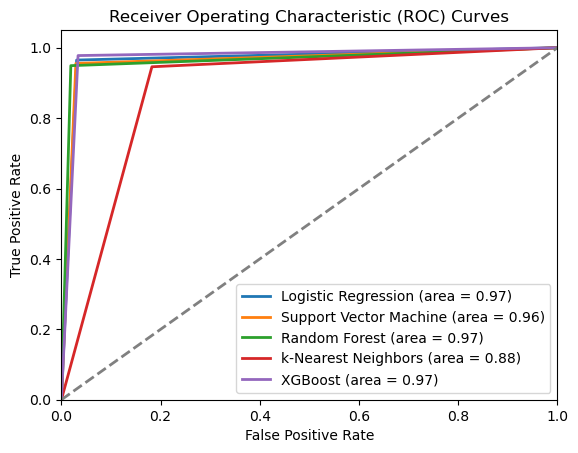

In [67]:
# ----------------------------------------------------------------------
# ROC curves of the tuned models on the test set
# ----------------------------------------------------------------------
# The curves are computed from the hard class predictions (0/1) of each tuned model, not from
# probability scores. Each curve therefore has a single operating point, and the reported AUC
# equals (TPR + TNR) / 2 at that point.
# Note: the loop variable `y` overwrites the target vector `y` defined earlier (last cell, no effect).
results = {
    "Logistic Regression": y_pred_logreg,
    "Support Vector Machine": y_pred_svc,
    "Random Forest": y_pred_rf,
    "k-Nearest Neighbors": y_pred_knn,
    "XGBoost":  y_pred_xgb
}

# "Random Forest": y_pred_rf, et "k-Nearest Neighbors": y_pred_knn ajout apres

plt.figure()

for name, y in results.items():
    
    fpr, tpr, _ = roc_curve(y_test, y)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label='%s (area = %0.2f)' % (name, roc_auc))
    #plt.fill_between(fpr, tpr, alpha=0.4)

# Plot the diagonal line representing random guessing
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')

# Customize the plot
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curves')
plt.legend(loc='lower right')

# Show the plot
plt.show()